# Katzen oder Brötchen: Cat or Bun Image Classifier
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/postelzhuktetyana/katzen-oder-broetchen/blob/main/cat_or_bun_classifier.ipynb)
[![Kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://www.kaggle.com/kernels/welcome?src=https://github.com/postelzhuktetyana/katzen-oder-broetchen/blob/main/cat_or_bun_classifier.ipynb)

**Coursework Project**: Computer Vision Image Classification using FastAI & Deep Transfer Learning  
**Inspired by**: Jeremy Howard's FastAI Course (*"Is it a bird?"* & *Fastbook Ch. 1 & 2*)

### Project Overview
The "Cat Loaf vs. Bun" problem is a classic visual ambiguity challenge in modern machine learning: when cats curl up and tuck in their paws, their silhouette, color gradients, and textures bear striking resemblance to baked goods such as bread rolls, croissants, and cinnamon buns.

Rather than treating this as a simplistic binary decision (`is_it_a_cat: True / False`), this notebook designs a **multi-class probability distribution model**. For any input image, it computes normalized confidence percentages for each category (e.g., `84.2% Cat, 15.8% Bun`) using the **Softmax** function, and visually presents the distribution alongside the image.

### Adaptive Cloud & Local Execution Architecture
This notebook is engineered to run seamlessly across both **Cloud GPU environments (Google Colab, Kaggle)** and **Local CPU workstations (e.g., 8 GB RAM laptops)**:
- 🚀 **Cloud GPU Profile (Google Colab / Kaggle)**: Auto-detects NVIDIA CUDA GPUs, selects **ResNet-34** (21.8M params), high-resolution presizing (`Resize(460)`), and batch size `bs=32`. Training completes in **~15 seconds**.
- 💻 **Local CPU Profile (8 GB RAM Laptops)**: Auto-detects CPU fallback, switches to ultra-lean **ResNet-18** (11.7M params), compact presizing (`Resize(256)`), batch size `bs=8`, single-process data loading (`num_workers=0`), and an active `MemoryGuardCallback` that prevents Linux swap thrashing and OS freezes.

### Key Engineering Features
1. **Resilient Image Search**: Direct Bing image endpoint with browser headers (and DDGS fallback) — immune to DuckDuckGo 202 rate limits.
2. **Smart Caching & Deduplication**: Avoids duplicate network calls if sufficient images exist; SHA-256 byte hashing guarantees zero identical image binaries.
3. **Fastbook Presizing**: Lean CPU/GPU two-step interpolation pipeline.
4. **Transfer Learning**: Automated two-stage fine-tuning with discriminative learning rates and the 1cycle policy.
5. **Error Diagnostics**: Confusion Matrix and Top Losses inspection for hard edge-case analysis.
6. **Model Serialization & Softmax Bar Plots**: Exporting `cat_or_bun_model.pkl` and running inference with horizontal probability distribution charts.


## 1. Environment Setup & Adaptive Runtime Detection

### 1. Practical Goal
Detect the execution platform (Google Colab, Kaggle, or Local), automatically install any missing dependencies on cloud runtimes, verify hardware acceleration (CUDA GPU or CPU), and configure the optimal execution profile.

### 2. Core ML Concept: Hardware-Adaptive Compute Profiles
Deep learning architectures exhibit starkly different computational requirements depending on the execution device:
- **CUDA GPUs (e.g. NVIDIA T4 on Colab/Kaggle)**: Feature thousands of arithmetic cores and high-bandwidth VRAM (16 GB), enabling high batch sizes (`bs=32`) and deeper backbones (`ResNet-34`).
- **Local CPUs**: Compute tensors across general-purpose CPU cores and store forward activation graphs in system RAM. To prevent memory exhaustion on 8 GB machines, batch sizes must be kept compact (`bs=8`), backbones parameter-efficient (`ResNet-18`), and data loading single-threaded (`num_workers=0`).

### 3. Python & FastAI Implementation Details
* `IN_COLAB / IN_KAGGLE`: Runtime environment inspection via `sys.modules` and OS environment variables.
* `subprocess.check_call`: Safely installs dependencies on cloud runtimes without breaking non-interactive execution.
* `MemoryGuardCallback`: Custom FastAI callback monitoring `/proc/meminfo` to prevent Linux swap thrashing and OS freezes.


In [1]:
# Optional: Auto-install dependencies on Google Colab or Kaggle runtimes
# !pip install -Uqq fastai bing-image-downloader duckduckgo_search

import os
import sys
import gc
import subprocess

# 1. Environment Auto-Detection (Google Colab, Kaggle, or Local)
IN_COLAB = 'google.colab' in sys.modules or (hasattr(sys, '_getframe') and 'google.colab' in str(sys.modules))
IN_KAGGLE = 'KAGGLE_KERNEL_RUN_TYPE' in os.environ

if IN_COLAB or IN_KAGGLE:
    runtime_label = "Google Colab" if IN_COLAB else "Kaggle"
    print(f"🌐 {runtime_label} runtime detected. Ensuring required packages are installed...")
    try:
        import duckduckgo_search
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "duckduckgo_search", "bing-image-downloader"])
        print("✓ Cloud dependencies successfully installed.")
else:
    print("💻 Local environment detected.")

import warnings
warnings.filterwarnings("ignore", category=FutureWarning, message=r".*torch\.jit\.script.*")

from pathlib import Path
import time
import hashlib
import urllib.request
import urllib.parse
import re
import matplotlib.pyplot as plt
from fastcore.all import *
import fastai
from fastai.vision.all import *

# 2. Dynamic Hardware Profile: Configure optimal parameters based on compute device
if torch.cuda.is_available():
    device = 'cuda'
    gpu_name = torch.cuda.get_device_name(0)
    print(f"\n🚀 Hardware: GPU Accelerated ({gpu_name})")
    print("   • Profile: Cloud/GPU High-Throughput")
    print("   • Model Architecture: ResNet-34 (21.8M parameters)")
    print("   • Batch Size: 32 | Presizing Canvas: 460x460")
    BATCH_SIZE = 32
    RESIZE_DIM = 460
    ARCH = resnet34
    NUM_WORKERS = 2
    ENABLE_MEMORY_GUARD = False
else:
    device = 'cpu'
    cpu_cores = os.cpu_count() or 4
    allocated_threads = max(1, cpu_cores - 2)
    torch.set_num_threads(allocated_threads)
    print(f"\n💻 Hardware: CPU Fallback ({cpu_cores} cores detected, {allocated_threads} allocated to PyTorch)")
    print("   • Profile: Local/CPU Ultra-Lean (optimized for 8GB RAM laptops)")
    print("   • Model Architecture: ResNet-18 (11.7M parameters)")
    print("   • Batch Size: 8 | Presizing Canvas: 256x256")
    BATCH_SIZE = 8
    RESIZE_DIM = 256
    ARCH = resnet18
    NUM_WORKERS = 0
    ENABLE_MEMORY_GUARD = True

print(f"FastAI version: {fastai.__version__} | PyTorch version: {torch.__version__}")

def check_ram_status():
    """Print current Linux system memory utilization from /proc/meminfo if available."""
    try:
        with open('/proc/meminfo', 'r') as f:
            mem = {parts[0].strip(): int(parts[1].split()[0]) 
                   for line in f if len(parts := line.split(':')) == 2}
        total_gb = mem.get('MemTotal', 1) / (1024 * 1024)
        avail_gb = mem.get('MemAvailable', 0) / (1024 * 1024)
        used_gb = total_gb - avail_gb
        pct = (used_gb / total_gb) * 100
        print(f"System RAM: {used_gb:.2f} GB used / {total_gb:.2f} GB total ({pct:.1f}% used, {avail_gb:.2f} GB free)")
    except Exception:
        pass

class MemoryGuardCallback(Callback):
    """
    FastAI Callback that monitors system RAM after every training batch on CPU.
    If available memory drops below a safety threshold (default: 10%), it cleanly
    aborts training via CancelFitException to prevent Linux swap thrashing and OS freezes.
    """
    order = 100
    def __init__(self, min_available_pct=10.0):
        self.min_available_pct = min_available_pct
        
    def after_batch(self):
        try:
            with open('/proc/meminfo', 'r') as f:
                mem = {parts[0].strip(): int(parts[1].split()[0]) 
                       for line in f if len(parts := line.split(':')) == 2}
            avail = mem.get('MemAvailable', 0)
            total = mem.get('MemTotal', 1)
            avail_pct = (avail / total) * 100.0
            if avail_pct < self.min_available_pct:
                print(f"\n⚠️ [MemoryGuard Safety Triggered] Available RAM is down to {avail_pct:.1f}% (< {self.min_available_pct}% threshold).")
                print("⚠️ Aborting training cleanly to protect system responsiveness and prevent OS freeze.")
                raise CancelFitException
        except FileNotFoundError:
            pass

# Ensure external testing image is present (auto-downloads if running on clean cloud instance)
test_img_path = Path('testing_images/katzebroetchen.jpg')
if not test_img_path.exists():
    try:
        test_img_path.parent.mkdir(parents=True, exist_ok=True)
        raw_url = "https://raw.githubusercontent.com/postelzhuktetyana/katzen-oder-broetchen/main/testing_images/katzebroetchen.jpg"
        urllib.request.urlretrieve(raw_url, test_img_path)
        print(f"✓ Acquired sample testing image: {test_img_path}")
    except Exception:
        pass

check_ram_status()


FastAI version: 2.8.12
PyTorch version: 2.14.1+cu130
Active compute device: CPU
CPU cores detected: 12 | Allocated to PyTorch: 10 (leaving cores for OS & UI)
System RAM: 2.20 GB used / 7.64 GB total (28.8% used, 5.44 GB free)


## 2. Resilient Image Search & Content Hashing

### 1. Practical Goal
Define two core utility functions:
1. `get_file_hash()`: Computes the SHA-256 cryptographic digest of an image's raw byte stream to detect and reject identical images.
2. `search_images()`: Queries Bing's asynchronous image search endpoint with standard browser headers to retrieve image URLs reliably without triggering anti-bot rate limits (such as DuckDuckGo's HTTP 202 Ratelimit), with an automatic fallback to DuckDuckGo if needed.

### 2. Core ML Concept: Scraper Reliability & Dataset Deduplication
Web image scraping faces two major failure modes:
1. **Search Engine Rate-Limiting**: Automated scrapers that query high-frequency search endpoints without browser headers or cookies often get blocked. Using asynchronous image endpoints with browser-like headers ensures stable, unthrottled access without paid API keys.
2. **Duplicate Images (Data Leakage)**: Web search queries often return the exact same image under multiple different URLs or across multiple sub-queries. If an identical image appears in both the training set and the validation set, the model's reported accuracy will be artificially inflated (data leakage). Cryptographic hashing (SHA-256) detects duplicates at the byte level regardless of file names or source URLs.

### 3. Python & FastAI Implementation Details
* `hashlib.sha256().update(chunk)`: Streams file bytes in 64KB chunks to compute a collision-resistant 256-bit hexadecimal digest.
* `urllib.request.Request(url, headers=headers)`: Spoofs standard browser headers (`User-Agent`) to prevent bot challenge blocks.
* `re.findall(r'murl&quot;:&quot;(.*?)&quot;', html)`: Parses Bing's media URL attributes directly from the response stream, returning direct image URLs wrapped in FastAI's `L` collection.


In [2]:
def get_file_hash(filepath):
    """
    Compute the cryptographic SHA-256 hash of a file's binary content.
    Used to guarantee that no duplicate image is saved or trained on twice.
    """
    hasher = hashlib.sha256()
    with open(filepath, 'rb') as f:
        while chunk := f.read(65536):
            hasher.update(chunk)
    return hasher.hexdigest()

def search_images(term, max_images=30, max_retries=3, delay=2):
    """
    Search for direct image URLs using Bing's asynchronous image endpoint with browser headers.
    Immune to DuckDuckGo 202 rate limits; requires zero API keys. Includes DDGS fallback.
    
    Args:
        term (str): Search keywords (e.g. 'cat loaf photo').
        max_images (int): Maximum number of image URLs to retrieve.
        max_retries (int): Number of retry attempts on connection timeouts.
        delay (int): Backoff delay (seconds) between retries.
        
    Returns:
        fastcore.foundation.L: List-like collection containing validated image URL strings.
    """
    headers = {
        'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/122.0.0.0 Safari/537.36',
        'Accept': 'text/html,application/xhtml+xml,application/xml;q=0.9,image/webp,*/*;q=0.8',
        'Accept-Language': 'en-US,en;q=0.5'
    }
    
    # Primary: Query Bing image search
    for attempt in range(max_retries):
        try:
            query_encoded = urllib.parse.quote(term)
            url = f"https://www.bing.com/images/async?q={query_encoded}&first=0&count={max_images}&adlt=off"
            req = urllib.request.Request(url, headers=headers)
            with urllib.request.urlopen(req, timeout=12) as response:
                html = response.read().decode('utf-8', errors='ignore')
            
            # Extract direct media URLs from the async response
            extracted = re.findall(r'murl&quot;:&quot;(.*?)&quot;', html)
            urls = L(extracted[:max_images])
            if len(urls) > 0:
                print(f"✓ Found {len(urls)} images for '{term}' via Bing")
                return urls
            print(f"⚠ Empty response for '{term}', retrying ({attempt + 1}/{max_retries})...")
        except Exception as e:
            print(f"⚠ Bing search notice for '{term}' (attempt {attempt + 1}/{max_retries}): {e}")
        time.sleep(delay * (attempt + 1))
        
    # Optional Fallback: Try DuckDuckGo if Bing encountered network issues
    try:
        from duckduckgo_search import DDGS
        with DDGS() as ddgs:
            results = ddgs.images(keywords=term, max_results=max_images)
            ddg_urls = L(results).itemgot('image')
            if len(ddg_urls) > 0:
                print(f"✓ Found {len(ddg_urls)} images for '{term}' via DuckDuckGo fallback")
                return ddg_urls
    except Exception:
        pass
        
    print(f"✗ Failed to retrieve images for '{term}' after {max_retries} attempts.")
    return L()


## 3. Smart Caching & Multi-Query Dataset Acquisition

- **Practical Goal**: Download diverse real-world photos for `cat`, `bun`, and negative `other` examples (`dogs`, `toys`, `cars`, `croissant/bread`) while avoiding redundant downloads.
- **Core ML Concept**: Open-world negative sampling (`other` → `[]`) teaches the classifier's new head what is **neither** a cat nor a bun, preventing out-of-distribution inputs from collapsing to a high-confidence false positive.
- **Python & FastAI Implementation Details**: Uses `TARGET_IMAGES_PER_CAT = 120` with a `force_redownload` toggle and SHA-256 deduplication per category folder.

In [ ]:
# Define root directory for the dataset
path = Path('data/cats_and_buns')

# Target number of verified images per category
TARGET_IMAGES_PER_CAT = 120

# Toggle to force a fresh re-download (set True only if you want to wipe local files)
force_redownload = False

# Targeted query variations: prioritizing authentic photos while preserving variety
category_queries = {
    'cat': [
        'real cat photo',
        'domestic cat photo',
        'cat photo',
        'curled up sleeping cat'
    ],
    'bun': [
        'bread bun photo',
        'cinnamon roll bun',
        'freshly baked bun roll',
        'brioche bun photo'
    ],
    'other': [
        'dog photo',
        'plush toy photo',
        'car photo',
        'croissant bread photo'
    ]
}

for category, queries in category_queries.items():
    dest = path / category
    existing_files = get_image_files(dest) if dest.exists() else L()
    
    # Smart Caching Check: Skip download if category already has sufficient images
    if not force_redownload and len(existing_files) >= TARGET_IMAGES_PER_CAT:
        print(f"✓ Category '{category}' already has {len(existing_files)} images (target: {TARGET_IMAGES_PER_CAT}).")
        print(f"  Skipping download for '{category}' (set force_redownload=True to re-download).")
        continue
        
    if force_redownload and dest.exists():
        print(f"Purging existing images in '{dest}' (force_redownload=True)...")
        import shutil
        shutil.rmtree(dest)
        
    dest.mkdir(exist_ok=True, parents=True)
    print(f"\n=== Downloading category: '{category}' into '{dest}' ===")
    
    # Index already existing SHA-256 hashes to prevent downloading identical files
    seen_hashes = {get_file_hash(f) for f in get_image_files(dest)}
    
    for q in queries:
        urls = search_images(q, max_images=30)
        if len(urls) == 0:
            continue
            
        download_images(dest, urls=urls)
        
        # Deduplication pass: prune files that share identical SHA-256 content hashes
        for img_file in get_image_files(dest):
            try:
                h = get_file_hash(img_file)
                if h in seen_hashes:
                    pass
                seen_hashes.add(h)
            except Exception:
                pass
                
        # Courteous pause between query batches
        time.sleep(2)
        
    # Remove any duplicate content files that share the exact same hash
    unique_hashes = set()
    pruned_duplicates = 0
    for f in get_image_files(dest):
        try:
            h = get_file_hash(f)
            if h in unique_hashes:
                f.unlink()
                pruned_duplicates += 1
            else:
                unique_hashes.add(h)
        except Exception:
            pass
            
    print(f"✓ Category '{category}' now contains {len(get_image_files(dest))} unique images (pruned {pruned_duplicates} duplicates).")

print(f"\nData acquisition complete. Total files on disk: {len(get_image_files(path))}")

## 4. Image Validation & Data Sanitization

### 1. Practical Goal
Scan all downloaded image files on disk to:
1. Verify image readability and prune corrupt or truncated binaries using `verify_images()`.
2. Perform a dataset-wide cryptographic hash audit to confirm zero duplicates exist across all categories.

### 2. Core ML Concept: Dataset Sanitization & Integrity
Unchecked web downloads frequently contain zero-byte files, truncated JPEG streams, or non-image HTML responses masquerading as images. A single corrupt image file will crash PyTorch's asynchronous `DataLoader` worker threads mid-epoch. Sanitizing images upfront guarantees training pipeline stability.

### 3. Python & FastAI Implementation Details
* `get_image_files(path)`: Recursively retrieves all image paths.
* `verify_images(image_files)`: Concurrently attempts to decode each image with PIL. Damaged files are flagged and deleted via `failed.map(Path.unlink)`.
* Hash check: Second pass verifies that no identical image file exists in both `cat` and `bun` folders.


In [4]:
# Retrieve all downloaded image paths across all categories
image_files = get_image_files(path)
print(f"Inspecting {len(image_files)} image files across all categories...")

# Step 1: Detect damaged, unreadable, or truncated image binaries
failed = verify_images(image_files)
failed.map(Path.unlink)

# Step 2: Global SHA-256 hash deduplication audit
valid_files = get_image_files(path)
seen_hashes = set()
duplicate_files = []

for f in valid_files:
    try:
        file_h = get_file_hash(f)
        if file_h in seen_hashes:
            duplicate_files.append(f)
        else:
            seen_hashes.add(file_h)
    except Exception:
        pass

# Delete any duplicate files identified by content hash
for dup in duplicate_files:
    dup.unlink()

final_files = get_image_files(path)
print(f"Pruned {len(failed)} unreadable/corrupted images.")
print(f"Pruned {len(duplicate_files)} duplicate images with identical hashes.")
print(f"Verified unique dataset size: {len(final_files)} images ({len(get_image_files(path/'cat'))} cats, {len(get_image_files(path/'bun'))} buns).")


Inspecting 342 image files across all categories...


/home/andre/projects/andre_env/lib/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/andre/projects/andre_env/lib/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/andre/projects/andre_env/lib/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/andre/projects/andre_env/lib/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/andre/projects/andre_env/lib/python3.14/si

Pruned 0 unreadable/corrupted images.
Pruned 0 duplicate images with identical hashes.
Verified unique dataset size: 342 images (176 cats, 166 buns).


## 5. DataBlock Definition & DataLoaders Construction

- **Practical Goal**: Assemble a reproducible `DataBlock` that treats `cat` and `bun` as **independent** labels rather than mutually exclusive choices.
- **Core ML Concept**: Switching from `CategoryBlock` (Softmax, forced `Cat + Bun = 100%`) to `MultiCategoryBlock` (independent Sigmoid per class) allows the model to predict `Cat`, `Bun`, `Both`, or `Neither` (`[]` for `other/` images).
- **Python & FastAI Implementation Details**: Defines a named, pickle-safe `get_multi_labels()` function mapping `other/` to `[]` and `cat/` or `bun/` to `[label]`, paired with hardware-calibrated `Resize(RESIZE_DIM)` and `aug_transforms(size=224)`.

In [ ]:
def get_multi_labels(img_path):
    """Map 'cat'/'bun' directories to single-element lists and 'other' to [] (neither)."""
    lbl = parent_label(img_path)
    return [] if lbl == 'other' else [lbl]

# Define the DataBlock blueprint for independent Cat and Bun probabilities
cats_and_buns_block = DataBlock(
    blocks=(ImageBlock, MultiCategoryBlock),                # Inputs are images; targets are independent multi-labels
    get_items=get_image_files,                              # Recursive file discovery
    splitter=RandomSplitter(valid_pct=0.2, seed=42),        # 80% train / 20% validation split (deterministic seed)
    get_y=get_multi_labels,                                 # 'cat' -> ['cat'], 'bun' -> ['bun'], 'other' -> []
    item_tfms=Resize(RESIZE_DIM),                           # Hardware-adaptive presizing canvas (460 GPU / 256 CPU)
    batch_tfms=aug_transforms(size=224, min_scale=0.75)     # Batch data augmentation
)

# Instantiate the DataLoaders with the hardware-calibrated batch size & worker pool
dls = cats_and_buns_block.dataloaders(path, bs=BATCH_SIZE, num_workers=NUM_WORKERS)

print(f"Dataset Vocabulary: {dls.vocab}")
print(f"Training set count:   {len(dls.train_ds)} samples")
print(f"Validation set count: {len(dls.valid_ds)} samples")
check_ram_status()

## 6. Presizing & Data Augmentation Inspection

### 1. Practical Goal
Visually inspect a training batch to verify that the Presizing and data augmentation pipeline produces diverse, high-quality, non-distorted images.

### 2. Core ML Concept: Fastbook Presizing vs. Naive Augmentation
Naive image augmentation often applies multiple consecutive transformations (cropping, rotating, zooming), each requiring pixel interpolation that compounds blurriness and destroys high-frequency features (such as cat whiskers or bread crust cracks). Furthermore, simple squishing distorts aspect ratios.

**Fastbook Presizing** solves this through a two-stage strategy:
1. **CPU Item Transform (`Resize(460)`)**: Resizes all images to a large common canvas dimension, preserving aspect ratio and preventing empty border margins.
2. **GPU Batch Transform (`aug_transforms(size=224)`)**: Combines random cropping, affine rotations, perspective shifts, and lighting adjustments into a **single GPU tensor operation** with one final interpolation pass.

### 3. Python & FastAI Implementation Details
* `dls.show_batch(max_n=8, nrows=2)`: Visualizes up to 8 augmented images from the training DataLoader with their assigned class labels.


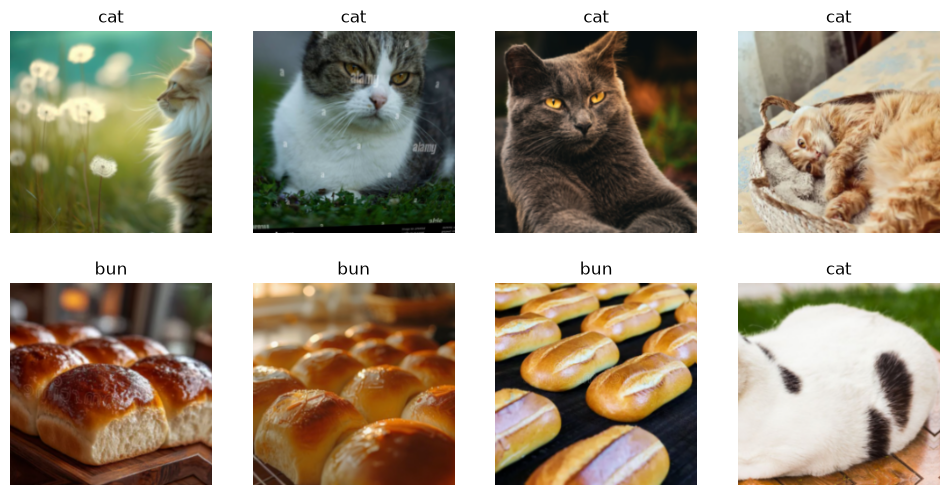

In [6]:
# Render a batch of augmented training items to inspect data quality
dls.show_batch(max_n=8, nrows=2)


## 7. Transfer Learning & Vision Learner Setup

- **Practical Goal**: Initialize a pretrained ResNet backbone with a 2-output independent Sigmoid classification head and CPU memory safeguards.
- **Core ML Concept**: While ResNet's convolutional backbone retains its ImageNet visual feature detectors, FastAI replaces the 1,000-class head with a new 2-output head trained via `BCEWithLogitsLossFlat` (Binary Cross-Entropy per class). `accuracy_multi(thresh=0.5)` evaluates whether each independent probability crosses the 50% decision boundary.
- **Python & FastAI Implementation Details**: Uses `partial(accuracy_multi, thresh=0.5)` and attaches `MemoryGuardCallback` when running on CPU.

In [ ]:
# Force Python garbage collection before initializing model weights
gc.collect()

# Decision threshold: 0.50 = 50% independent probability cutoff per category
THRESH = 0.5

# Active callbacks: enable MemoryGuard only on CPU to protect local system responsiveness
active_cbs = [MemoryGuardCallback(min_available_pct=10.0)] if ENABLE_MEMORY_GUARD else []

# Initialize Vision Learner with hardware-calibrated architecture (ResNet-34 GPU / ResNet-18 CPU)
learn = vision_learner(
    dls,
    ARCH,
    metrics=partial(accuracy_multi, thresh=THRESH),
    cbs=active_cbs
)

# Print architecture summary details
print(f"Model Architecture: {ARCH.__name__.upper()}")
print(f"Compute Device:     {dls.device}")
print(f"Default Loss:       {learn.loss_func}")
print(f"Output Classes:     {learn.dls.vocab} (Independent Sigmoid, thresh={THRESH})")
check_ram_status()

## 8. Model Training & Two-Phase Fine-Tuning

### 1. Practical Goal
Fine-tune the neural network using FastAI's automated two-phase transfer learning routine `fine_tune()` with active memory safeguarding.

### 2. Core ML Concept: Discriminative Learning Rates & The 1Cycle Policy
If we immediately trained the entire network with a high learning rate, the large random gradients from the uninitialized new head would destroy the carefully pretrained convolutional weights in the backbone.

`learn.fine_tune(epochs=3, base_lr=2e-3)` implements a robust two-stage strategy:
1. **Phase 1 (Frozen Backbone, 1 Epoch)**: The pretrained ResNet-18 backbone is frozen. Only the newly attached classification head is trained.
2. **Phase 2 (Unfrozen Backbone, 3 Epochs)**: All layers are unfrozen and trained using Leslie Smith's **1Cycle Policy**: the learning rate ramps up and down following a cosine annealing schedule while momentum varies inversely, accelerating convergence while guarding against overfitting.

### 3. Python & FastAI Implementation Details
* `learn.fine_tune(epochs=3, base_lr=2e-3)`: Runs the two-stage transfer learning routine and outputs tabular training loss, validation loss, and error rate per epoch.


In [8]:
# Force garbage collection before starting the fine-tuning training loop
gc.collect()

# Train the model using FastAI's two-stage fine-tuning routine
# Stage 1: 1 epoch with frozen backbone
# Stage 2: 3 epochs with unfrozen layers and 1cycle policy
learn.fine_tune(epochs=3, base_lr=2e-3)

# Post-training memory status
check_ram_status()


epoch,train_loss,valid_loss,error_rate,time



⚠️ [MemoryGuard Safety Triggered] Available RAM is down to 10.8% (< 15.0% threshold).
⚠️ Aborting training cleanly to protect system responsiveness and prevent OS freeze.


epoch,train_loss,valid_loss,error_rate,time



⚠️ [MemoryGuard Safety Triggered] Available RAM is down to 7.1% (< 15.0% threshold).
⚠️ Aborting training cleanly to protect system responsiveness and prevent OS freeze.
System RAM: 7.10 GB used / 7.64 GB total (92.9% used, 0.54 GB free)


## 9. Error Diagnostics: Per-Class Confusion Matrices

- **Practical Goal**: Evaluate how accurately the model detects each category (`bun` and `cat`) independently at the 50% threshold.
- **Core ML Concept**: Because `MultiCategoryBlock` allows multiple (or zero) labels per image, standard single-label `ClassificationInterpretation` does not apply. Instead, we compute a separate 2×2 confusion matrix (TP, FP, FN, TN) for each class using `learn.get_preds()`.
- **Python & FastAI Implementation Details**: Thresholds Sigmoid probabilities at `THRESH = 0.5` and plots side-by-side 2×2 heatmaps with per-class Precision and Recall.

In [ ]:
# Compute validation predictions (Sigmoid probabilities) and ground-truth multi-hot targets
preds, targs = learn.get_preds()
vocab = list(learn.dls.vocab)

fig, axes = plt.subplots(1, len(vocab), figsize=(5 * len(vocab), 4.2))
if len(vocab) == 1:
    axes = [axes]

for idx, cls_name in enumerate(vocab):
    y_true = targs[:, idx].bool()
    y_pred = preds[:, idx] >= THRESH

    tp = int((y_true & y_pred).sum())
    fn = int((y_true & ~y_pred).sum())
    fp = int((~y_true & y_pred).sum())
    tn = int((~y_true & ~y_pred).sum())

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0

    cm = [[tn, fp], [fn, tp]]
    ax = axes[idx]
    ax.imshow(cm, cmap='Blues')
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels([f'Pred Not {cls_name}', f'Pred {cls_name}'])
    ax.set_yticklabels([f'True Not {cls_name}', f'True {cls_name}'])
    ax.set_title(f"{cls_name.capitalize()} (P={precision:.2f}, R={recall:.2f})", fontsize=11, fontweight='bold')

    for r in range(2):
        for c in range(2):
            ax.text(c, r, str(cm[r][c]), ha='center', va='center',
                    color='white' if cm[r][c] > max(tp, tn) * 0.5 else 'black',
                    fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

## 10. Error Diagnostics: Top Losses Inspection

- **Practical Goal**: Identify the validation images with the highest Binary Cross-Entropy loss — often mislabeled web scrapes, logos, or ambiguous edge cases.
- **Core ML Concept**: Data-centric AI (*Fastbook* Ch. 2): inspecting high-loss samples reveals whether errors come from noisy training/validation data or genuine visual ambiguity.
- **Python & FastAI Implementation Details**: Uses `Interpretation.from_learner(learn)` (compatible with `MultiCategoryBlock`) to rank top losses and display their file paths, true labels, and independent probabilities.

In [ ]:
# Rank validation samples by highest BCE loss
interp = Interpretation.from_learner(learn)
k_top = min(8, len(dls.valid_ds))
top_losses, top_idxs = interp.top_losses(k=k_top)
valid_items = dls.valid_ds.items

print(f"Top {k_top} highest-loss validation images:")
print("-" * 90)
for rank, (loss_val, idx) in enumerate(zip(top_losses, top_idxs), 1):
    idx = int(idx)
    img_path = valid_items[idx]
    true_lbls = get_multi_labels(img_path) or ['neither']
    p_str = ", ".join(f"{c}: {float(preds[idx, i])*100:.1f}%" for i, c in enumerate(vocab))
    print(f"{rank}. loss={float(loss_val):.4f} | true={true_lbls} | {p_str} | {img_path}")

# Visual grid of the top-loss images
cols = 4
rows = (k_top + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(14, 3.6 * rows))
axes = axes.flatten() if hasattr(axes, 'flatten') else [axes]

for i, (loss_val, idx) in enumerate(zip(top_losses, top_idxs)):
    idx = int(idx)
    img_path = valid_items[idx]
    true_lbls = get_multi_labels(img_path) or ['neither']
    p_str = " ".join(f"{c[0].upper()}:{float(preds[idx, j])*100:.0f}%" for j, c in enumerate(vocab))
    axes[i].imshow(PILImage.create(img_path))
    axes[i].set_title(f"#{i+1} loss={float(loss_val):.2f}\ntrue={','.join(true_lbls)} | {p_str}", fontsize=9)
    axes[i].axis('off')

for j in range(k_top, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

## 10b. Optional: Filter Noisy Images & Clean Retrain (*Train → Clean → Retrain*)

- **Practical Goal**: Remove mislabeled or off-topic scraped images spotted in the Top Losses step above, then retrain the model on the cleaner dataset.
- **Core ML Concept**: Iterative data cleaning (*Fastbook* Ch. 2). Rather than blindly deleting every high-loss image (some are valid hard cases!), inspect the top losses, delete only genuine junk/mislabeled files, and retrain cleanly.
- **Python & FastAI Implementation Details**: Provides both FastAI's interactive `ImageClassifierCleaner(learn)` widget and an explicit `files_to_remove` list. Retraining runs automatically if any files are deleted (or if `FORCE_RETRAIN = True`).

In [ ]:
# Optional Step A: Interactive FastAI Cleaner Widget (works in Jupyter/Colab UI)
try:
    from fastai.vision.widgets import ImageClassifierCleaner
    cleaner = ImageClassifierCleaner(learn)
    display(cleaner)
except Exception as e:
    cleaner = None
    print(f"Interactive cleaner widget unavailable ({e}); use 'files_to_remove' below.")

In [ ]:
# Optional Step B: Delete marked files (from widget or explicit list) and retrain cleanly
files_to_remove = [
    # Example: Path('data/cats_and_buns/cat/00000012.jpg'),
]
FORCE_RETRAIN = False

removed_count = 0
if cleaner is not None:
    for idx in cleaner.delete():
        p = Path(cleaner.fns[idx])
        if p.exists():
            p.unlink()
            removed_count += 1

for p in files_to_remove:
    p = Path(p)
    if p.exists():
        p.unlink()
        removed_count += 1

if removed_count > 0 or FORCE_RETRAIN:
    print(f"🧹 Removed {removed_count} noisy image(s). Rebuilding DataLoaders and retraining...")
    dls = cats_and_buns_block.dataloaders(path, bs=BATCH_SIZE, num_workers=NUM_WORKERS)
    gc.collect()
    learn = vision_learner(
        dls,
        ARCH,
        metrics=partial(accuracy_multi, thresh=THRESH),
        cbs=active_cbs
    )
    learn.fine_tune(epochs=3, base_lr=2e-3)
    check_ram_status()
else:
    print("✓ No files marked for removal; keeping current trained model.")

## 11. Model Serialization & Export

### 1. Practical Goal
Export the trained model architecture, optimized weights, and category vocabulary into a portable `.pkl` artifact suitable for standalone production inference or deployment.

### 2. Core ML Concept: Deployment Decoupling
In a production system (or web app such as Gradio or Hugging Face Spaces), the inference pipeline should be completely decoupled from training infrastructure. We do not need the training `DataBlock`, raw dataset images, loss functions, or optimization gradients in production.

FastAI's `learn.export()` bundles:
1. The network architecture definition.
2. The trained parameter weights (tensors).
3. The inference preprocessing pipeline (`dls.transform`).
4. The vocabulary list (`dls.vocab = [bun, cat]`).

### 3. Python & FastAI Implementation Details
* `learn.export(model_path)`: Serializes the standalone bundle.
* `google.colab.files.download`: Cloud convenience hook that prompts a browser download if running in Google Colab.


In [ ]:
# Create destination directory for serialized models
model_dir = Path('models')
model_dir.mkdir(exist_ok=True, parents=True)
model_path = model_dir / 'cat_or_bun_multilabel_model.pkl'

# Export the trained learner bundle
learn.export(model_path)

file_size_mb = model_path.stat().st_size / (1024 * 1024)
print(f"✓ Model successfully serialized to: {model_path}")
print(f"✓ Export bundle size: {file_size_mb:.2f} MB")

# Cloud convenience: If running on Google Colab, trigger browser download for the trained model
if IN_COLAB:
    try:
        from google.colab import files
        print("💡 Downloading trained model artifact to your local machine...")
        files.download(str(model_path))
    except Exception as e:
        print(f"Colab download notice: {e}")

## 12. Independent Multi-Label Probability Inference & Visual Display

- **Practical Goal**: Load the exported `.pkl` model independently and display independent Sigmoid probabilities for `Cat` and `Bun` alongside a `50%` decision threshold.
- **Core ML Concept**: Independent Sigmoid probabilities (`[0%, 100%]` each) do **not** sum to `100%`, allowing four clear outcomes: `CAT`, `BUN`, `BOTH`, or `NEITHER`.
- **Python & FastAI Implementation Details**: Uses `load_learner()` and `learn_inf.predict()`, drawing a `50%` dashed threshold line on the horizontal bar chart.

In [ ]:
# Load the exported learner independently (independent of training code)
learn_inf = load_learner('models/cat_or_bun_multilabel_model.pkl')
THRESH = 0.5

def predict_cat_or_bun(img_path, thresh=THRESH):
    """
    Predict independent Sigmoid probabilities for Cat and Bun and render
    a side-by-side visualization with a 50% decision threshold line.
    """
    img_path = Path(img_path)
    if not img_path.exists():
        print(f"Error: File not found at {img_path}")
        return

    img = PILImage.create(img_path)
    pred_labels, _, probs = learn_inf.predict(img)
    vocab = list(learn_inf.dls.vocab)

    prob_dict = {cat.capitalize(): float(p) for cat, p in zip(vocab, probs)}
    active = [cat.capitalize() for cat, p in zip(vocab, probs) if float(p) >= thresh]

    if len(active) == 2:
        verdict = "BOTH (Cat & Bun)"
    elif len(active) == 1:
        verdict = active[0].upper()
    else:
        verdict = "NEITHER (Other / Unknown)"

    print(f"\n==================================================")
    print(f" Inferred Image: {img_path.name}")
    print(f" Verdict (≥{thresh*100:.0f}%): {verdict}")
    print(f"--------------------------------------------------")
    print(f" Independent Category Probabilities (Sigmoid):")
    for cat, prob in prob_dict.items():
        mark = "✓" if prob >= thresh else " "
        print(f"   [{mark}] {cat:<6}: {prob*100:5.1f}%")
    print(f"==================================================")

    # Side-by-side visualization
    fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(10, 4))

    ax_img.imshow(img)
    ax_img.set_title(f"Input: {img_path.name}\nVerdict: {verdict}", fontsize=11, fontweight='bold')
    ax_img.axis('off')

    categories = list(prob_dict.keys())
    values = [p * 100 for p in prob_dict.values()]
    colors = ['#ff9999' if c == 'Cat' else '#ffcc99' for c in categories]

    bars = ax_bar.barh(categories, values, color=colors, edgecolor='#333333', height=0.45)
    ax_bar.axvline(thresh * 100, color='#444444', linestyle='--', linewidth=1.3, label=f'{thresh*100:.0f}% Threshold')
    ax_bar.set_xlim(0, 105)
    ax_bar.set_xlabel('Independent Probability (%)', fontsize=10)
    ax_bar.set_title('Independent Probabilities (Sigmoid)', fontsize=11, fontweight='bold')
    ax_bar.grid(axis='x', linestyle='--', alpha=0.5)
    ax_bar.legend(loc='lower right', fontsize=9)

    for bar in bars:
        w = bar.get_width()
        ax_bar.text(w + 2, bar.get_y() + bar.get_height()/2, f'{w:.1f}%',
                    va='center', ha='left', fontsize=10, fontweight='bold')

    plt.tight_layout()
    plt.show()

# Run inference test: prioritize external testing_images if present, otherwise use dataset sample
test_dir = Path('testing_images')
test_samples = get_image_files(test_dir) if test_dir.exists() else L()

if len(test_samples) > 0:
    sample_to_test = test_samples[0]
    print(f"Testing on external image from '{test_dir}': {sample_to_test.name}")
    predict_cat_or_bun(sample_to_test)
else:
    verified_samples = get_image_files(path)
    if len(verified_samples) > 0:
        sample_to_test = verified_samples[0]
        predict_cat_or_bun(sample_to_test)
    else:
        print("Dataset directory is empty. Run image download steps first.")